<a href="https://colab.research.google.com/github/badriahalkhaldi/programming-for-AI-and-Data-Science/blob/main/bigDataLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30)

df = pd.read_csv('/content/AirQuality_visualization.csv', sep=';')
print(df.shape)
df.head()


(9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,",,,,,"
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,","
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


In [21]:
df = df.rename(columns={'T': 'Temperature'})
df = df.rename(columns={'RH': 'Relative Humidity'})
df = df.rename(columns={'AH': 'Absolute Humidity'})
df.columns.tolist()

['Date',
 'Time',
 'CO(GT)',
 'PT08.S1(CO)',
 'NMHC(GT)',
 'C6H6(GT)',
 'PT08.S2(NMHC)',
 'NOx(GT)',
 'PT08.S3(NOx)',
 'NO2(GT)',
 'PT08.S4(NO2)',
 'PT08.S5(O3)',
 'Temperature',
 'Relative Humidity',
 'Absolute Humidity',
 'Unnamed: 15',
 ',,,,,']

In [22]:
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Temperature,Relative Humidity,Absolute Humidity,Unnamed: 15,",,,,,"
0,10/03/2004,18.00.00,"2,6",1360.0,150.0,"11,9",1046.0,166.0,1056.0,113.0,1692.0,1268.0,"13,6","48,9","0,7578",NaN,NaN
1,10/03/2004,19.00.00,2,1292.0,112.0,"9,4",955.0,103.0,1174.0,92.0,1559.0,972.0,"13,3","47,7","0,7255",NaN,","
2,10/03/2004,20.00.00,"2,2",1402.0,88.0,"9,0",939.0,131.0,1140.0,114.0,1555.0,1074.0,"11,9","54,0","0,7502",NaN,NaN
3,10/03/2004,21.00.00,"2,2",1376.0,80.0,"9,2",948.0,172.0,1092.0,122.0,1584.0,1203.0,"11,0","60,0","0,7867",NaN,NaN
4,10/03/2004,22.00.00,"1,6",1272.0,51.0,"6,5",836.0,131.0,1205.0,116.0,1490.0,1110.0,"11,2","59,6","0,7888",NaN,NaN


In [23]:
junk = [c for c in df.columns if c.startswith('Unnamed') or ',' in c]
print('Dropping:', junk)
df = df.drop(junk, axis=1)
df.shape

Dropping: ['Unnamed: 15', ',,,,,']


(9471, 15)

In [24]:
for c in ['CO(GT)', 'C6H6(GT)', 'Temperature', 'Relative Humidity', 'Absolute Humidity']:
    df[c] = df[c].str.replace(',', '.').astype(float)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               9357 non-null   object 
 1   Time               9357 non-null   object 
 2   CO(GT)             9357 non-null   float64
 3   PT08.S1(CO)        9357 non-null   float64
 4   NMHC(GT)           9357 non-null   float64
 5   C6H6(GT)           9357 non-null   float64
 6   PT08.S2(NMHC)      9357 non-null   float64
 7   NOx(GT)            9357 non-null   float64
 8   PT08.S3(NOx)       9357 non-null   float64
 9   NO2(GT)            9357 non-null   float64
 10  PT08.S4(NO2)       9357 non-null   float64
 11  PT08.S5(O3)        9357 non-null   float64
 12  Temperature        9357 non-null   float64
 13  Relative Humidity  9357 non-null   float64
 14  Absolute Humidity  9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               9357 non-null   object 
 1   Time               9357 non-null   object 
 2   CO(GT)             9357 non-null   float64
 3   PT08.S1(CO)        9357 non-null   float64
 4   NMHC(GT)           9357 non-null   float64
 5   C6H6(GT)           9357 non-null   float64
 6   PT08.S2(NMHC)      9357 non-null   float64
 7   NOx(GT)            9357 non-null   float64
 8   PT08.S3(NOx)       9357 non-null   float64
 9   NO2(GT)            9357 non-null   float64
 10  PT08.S4(NO2)       9357 non-null   float64
 11  PT08.S5(O3)        9357 non-null   float64
 12  Temperature        9357 non-null   float64
 13  Relative Humidity  9357 non-null   float64
 14  Absolute Humidity  9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [26]:
duplicate_count = df.duplicated().sum()
print(f'Number of duplicate rows: {duplicate_count}')
df = df.drop_duplicates()
df.shape

Number of duplicate rows: 113


(9358, 15)

In [27]:
print((df == -200).sum())

Date                    0
Time                    0
CO(GT)               1683
PT08.S1(CO)           366
NMHC(GT)             8443
C6H6(GT)              366
PT08.S2(NMHC)         366
NOx(GT)              1639
PT08.S3(NOx)          366
NO2(GT)              1642
PT08.S4(NO2)          366
PT08.S5(O3)           366
Temperature           366
Relative Humidity     366
Absolute Humidity     366
dtype: int64


In [28]:
print((df == -200).sum().sum())

16701


In [30]:
df = df.replace(-200, np.nan)


In [31]:
df.isna().sum()

,0
Date,1
Time,1
CO(GT),1684
PT08.S1(CO),367
NMHC(GT),8444
C6H6(GT),367
PT08.S2(NMHC),367
NOx(GT),1640
PT08.S3(NOx),367
NO2(GT),1643


In [32]:
#df = df.drop('NMHC(GT)', axis=1)
df = df.dropna()
print(df.isna().sum(), 'missing values left;',df.shape)

Date                 0
Time                 0
CO(GT)               0
PT08.S1(CO)          0
NMHC(GT)             0
C6H6(GT)             0
PT08.S2(NMHC)        0
NOx(GT)              0
PT08.S3(NOx)         0
NO2(GT)              0
PT08.S4(NO2)         0
PT08.S5(O3)          0
Temperature          0
Relative Humidity    0
Absolute Humidity    0
dtype: int64 missing values left; (827, 15)


In [33]:
df['Absolute Humidity'] = df['Absolute Humidity'].multiply(100)
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Temperature,Relative Humidity,Absolute Humidity
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,75.78
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,72.55
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,75.02
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,78.67
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,78.88


In [35]:
def remove_outliers(column):
    Q1 = column.quantile(0.25)
    Q3 = column.quantile(0.75)
    IQR = Q3 - Q1
    threshold = 1.5 * IQR
    outlier_mask = (column < Q1 - threshold) | (column > Q3 + threshold)
    return column.mask(outlier_mask)  # outlier values become NaN, the rows stay



In [60]:
col_name = ['CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'Temperature', 'Relative Humidity', 'Absolute Humidity']
for col in col_name:
    df[col] = remove_outliers(df[col])

df.isna().sum()

,0
Date,0
Time,0
CO(GT),22
PT08.S1(CO),5
NMHC(GT),41
C6H6(GT),18
PT08.S2(NMHC),2
NOx(GT),17
PT08.S3(NOx),15
NO2(GT),2


In [61]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Temperature,Relative Humidity,Absolute Humidity,Year,Month
0,2004-03-10,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,75.78,2004,3
1,2004-03-10,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,72.55,2004,3
2,2004-03-10,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,75.02,2004,3
3,2004-03-10,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,78.67,2004,3
4,2004-03-10,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,78.88,2004,3


In [62]:
df.describe()

,Date,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),Temperature,Relative Humidity,Absolute Humidity,Year,Month
count,827,805.000000,822.000000,786.000000,809.000000,825.000000,810.000000,812.000000,825.000000,812.000000,824.000000,814.000000,827.000000,788.000000,827.0,827.000000
mean,2004-04-04 02:50:38.452237056,2.236770,1203.203163,200.628499,10.256737,964.226667,138.513580,947.818966,100.030303,1584.136700,1041.308252,15.389803,49.050181,80.951510,2004.0,3.545345
min,2004-03-10 00:00:00,0.300000,753.000000,7.000000,0.500000,448.000000,12.000000,461.000000,19.000000,955.000000,263.000000,6.300000,14.900000,44.050000,2004.0,3.000000
25%,2004-03-24 00:00:00,1.300000,1016.250000,73.000000,4.800000,754.000000,81.000000,764.750000,78.000000,1364.750000,759.750000,11.800000,36.700000,71.167500,2004.0,3.000000
50%,2004-04-02 00:00:00,2.000000,1171.000000,150.500000,9.000000,943.000000,127.000000,913.500000,99.000000,1551.500000,1006.000000,14.900000,49.600000,80.855000,2004.0,4.000000
75%,2004-04-15 00:00:00,3.000000,1374.750000,278.000000,14.500000,1142.000000,183.750000,1106.250000,122.000000,1776.000000,1315.750000,18.200000,60.550000,90.932500,2004.0,4.000000
max,2004-05-01 00:00:00,5.800000,1917.000000,680.000000,29.800000,1701.000000,342.000000,1643.000000,187.000000,2396.000000,2122.000000,27.700000,83.200000,120.160000,2004.0,5.000000
std,NaN,1.231576,234.954073,162.228908,6.627938,263.962524,74.844811,242.159404,31.183769,279.164311,393.791857,4.560190,15.266746,14.702498,0.0,0.500665


In [63]:
subset_1 = df[['Date', 'Time', 'CO(GT)', 'NO2(GT)']]
subset_2 = df[['Date', 'Time', 'Temperature', 'Relative Humidity']]
subset_1.head()

,Date,Time,CO(GT),NO2(GT)
0,2004-03-10,18.00.00,2.6,113.0
1,2004-03-10,19.00.00,2.0,92.0
2,2004-03-10,20.00.00,2.2,114.0
3,2004-03-10,21.00.00,2.2,122.0
4,2004-03-10,22.00.00,1.6,116.0


In [64]:
hot = df[df['Temperature'] > 30]
hot.shape

(0, 17)

In [65]:
merged_data = pd.merge(subset_1, subset_2, on=['Date', 'Time'])
print(merged_data.shape)
merged_data.head()

(827, 6)


,Date,Time,CO(GT),NO2(GT),Temperature,Relative Humidity
0,2004-03-10,18.00.00,2.6,113.0,13.6,48.9
1,2004-03-10,19.00.00,2.0,92.0,13.3,47.7
2,2004-03-10,20.00.00,2.2,114.0,11.9,54.0
3,2004-03-10,21.00.00,2.2,122.0,11.0,60.0
4,2004-03-10,22.00.00,1.6,116.0,11.2,59.6


In [66]:
merged_data.sort_values(by='CO(GT)', ascending=False).head(10)

,Date,Time,CO(GT),NO2(GT),Temperature,Relative Humidity
101,2004-03-15,10.00.00,5.8,157.0,17.4,45.6
643,2004-04-16,17.00.00,5.7,142.0,14.6,76.0
156,2004-03-17,21.00.00,5.7,180.0,19.1,42.6
821,2004-04-30,19.00.00,5.7,135.0,19.8,58.6
656,2004-04-23,08.00.00,5.6,123.0,15.4,53.3
667,2004-04-23,19.00.00,5.6,161.0,23.1,36.7
392,2004-04-01,19.00.00,5.5,164.0,20.8,36.7
765,2004-04-28,07.00.00,5.5,104.0,15.0,58.3
415,2004-04-02,20.00.00,5.5,168.0,19.4,42.5
99,2004-03-15,08.00.00,5.5,114.0,12.4,63.9


In [67]:
df.sort_values(by=['Month', 'CO(GT)'], ascending=[True, False])[['Date', 'Time', 'Month',
'CO(GT)']].head(10)

,Date,Time,Month,CO(GT)
112,2004-03-15,10.00.00,3,5.8
171,2004-03-17,21.00.00,3,5.7
110,2004-03-15,08.00.00,3,5.5
53,2004-03-12,23.00.00,3,5.4
136,2004-03-16,10.00.00,3,5.3
361,2004-03-25,19.00.00,3,5.2
147,2004-03-16,21.00.00,3,5.1
168,2004-03-17,18.00.00,3,5.0
24,2004-03-11,18.00.00,3,4.8
182,2004-03-18,08.00.00,3,4.7


In [68]:
merged_data.head().T

,0,1,2,3,4
Date,2004-03-10 00:00:00,2004-03-10 00:00:00,2004-03-10 00:00:00,2004-03-10 00:00:00,2004-03-10 00:00:00
Time,18.00.00,19.00.00,20.00.00,21.00.00,22.00.00
CO(GT),2.6,2.0,2.2,2.2,1.6
NO2(GT),113.0,92.0,114.0,122.0,116.0
Temperature,13.6,13.3,11.9,11.0,11.2
Relative Humidity,48.9,47.7,54.0,60.0,59.6


In [69]:
long_data = pd.melt(df.head(), id_vars=['Date', 'Time'], value_vars=['CO(GT)', 'NO2(GT)'],
var_name='Gas', value_name='Reading')
print(long_data.shape)
long_data

(10, 4)


,Date,Time,Gas,Reading
0,2004-03-10,18.00.00,CO(GT),2.6
1,2004-03-10,19.00.00,CO(GT),2.0
2,2004-03-10,20.00.00,CO(GT),2.2
3,2004-03-10,21.00.00,CO(GT),2.2
4,2004-03-10,22.00.00,CO(GT),1.6
5,2004-03-10,18.00.00,NO2(GT),113.0
6,2004-03-10,19.00.00,NO2(GT),92.0
7,2004-03-10,20.00.00,NO2(GT),114.0
8,2004-03-10,21.00.00,NO2(GT),122.0
9,2004-03-10,22.00.00,NO2(GT),116.0


In [70]:
co_table = df.pivot_table(index='Month', columns='Year', values='CO(GT)', aggfunc='mean')
co_table

Year,2004
Month,
3,2.189589
4,2.273121
5,3.500000


In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

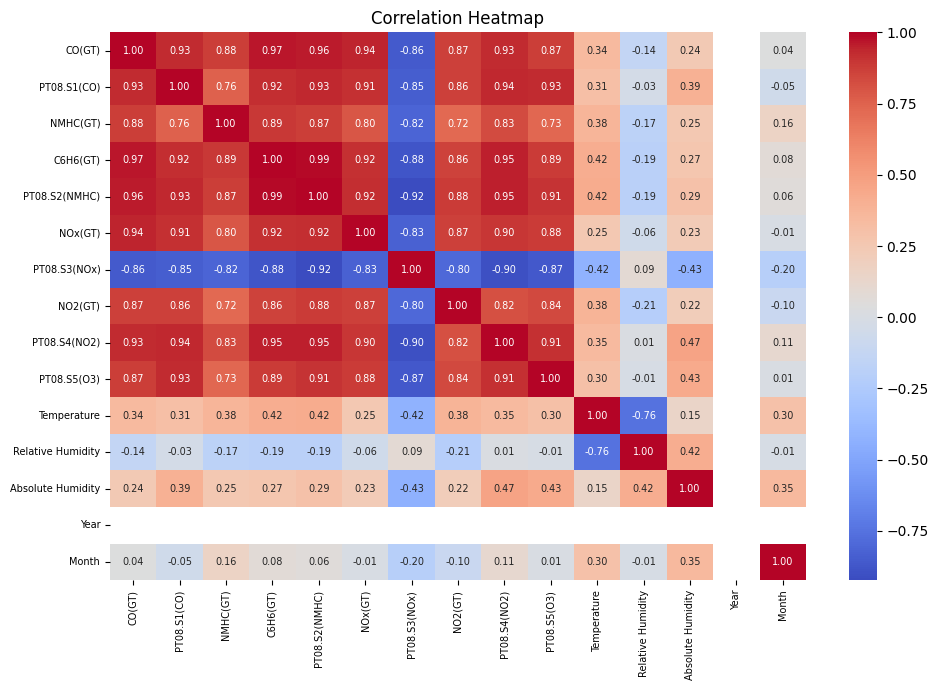

In [72]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes('number').corr(), annot=True,
annot_kws={'size': 7}, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

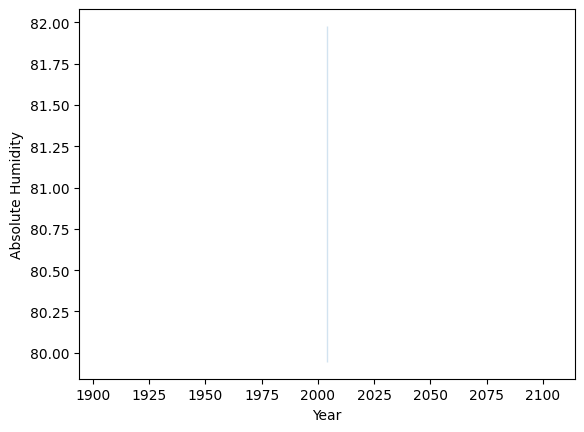

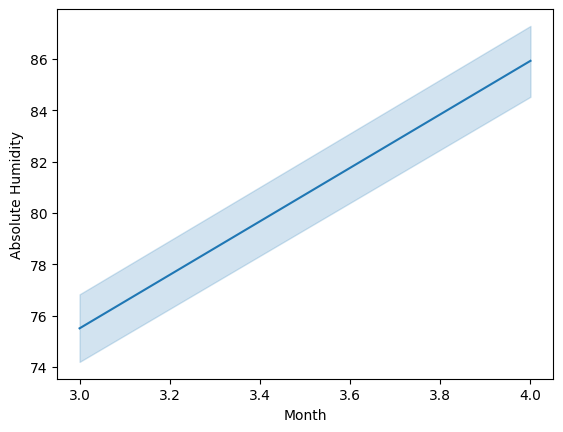

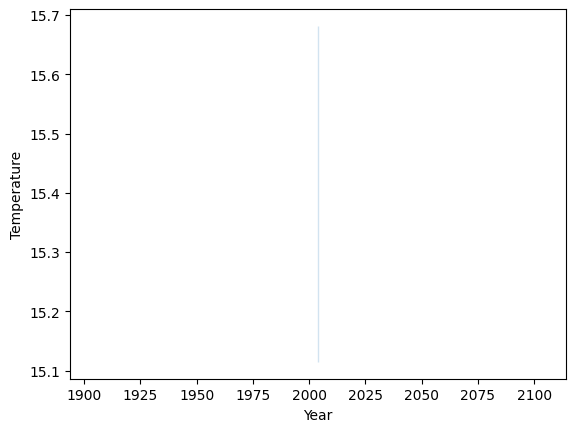

In [73]:
sns.lineplot(df, x='Year', y='Absolute Humidity')
plt.show()
sns.lineplot(df, x='Month', y='Absolute Humidity')
plt.show()
sns.lineplot(df, x='Year', y='Temperature')
plt.show()

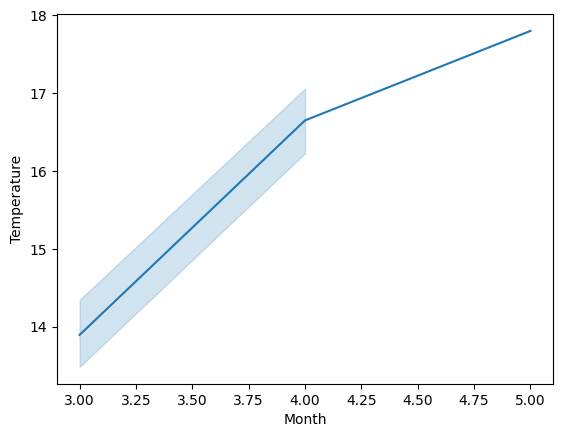

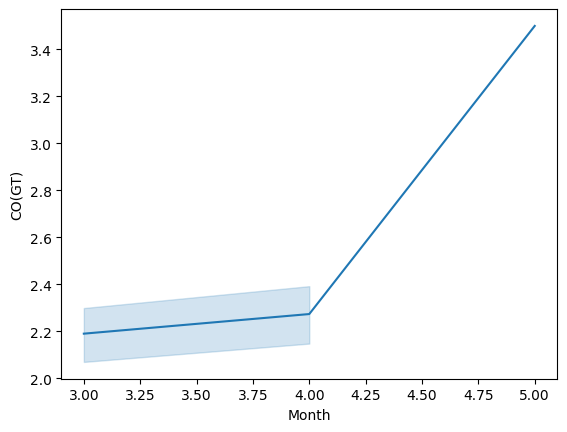

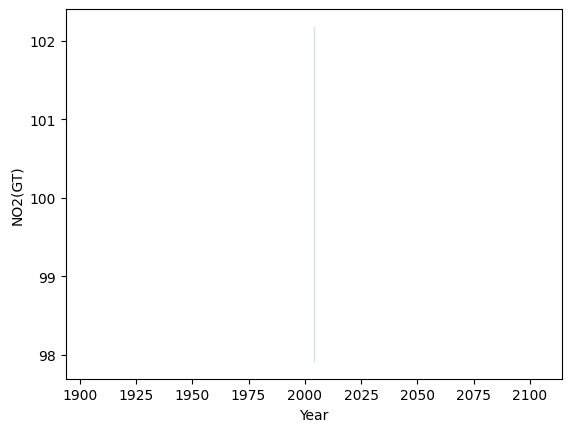

In [74]:
sns.lineplot(df, x='Month', y='Temperature')
plt.show()
sns.lineplot(df, x='Month', y='CO(GT)')
plt.show()
sns.lineplot(df, x='Year', y='NO2(GT)')
plt.show()

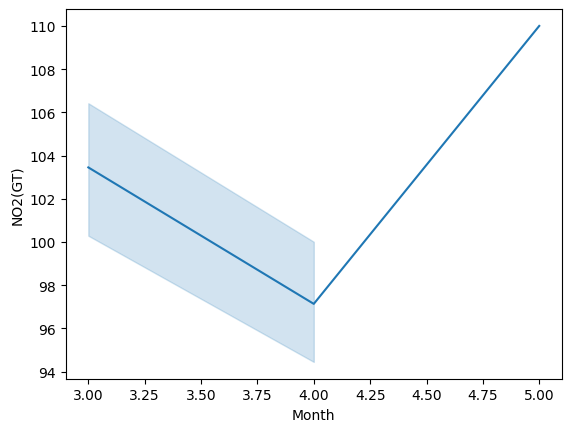

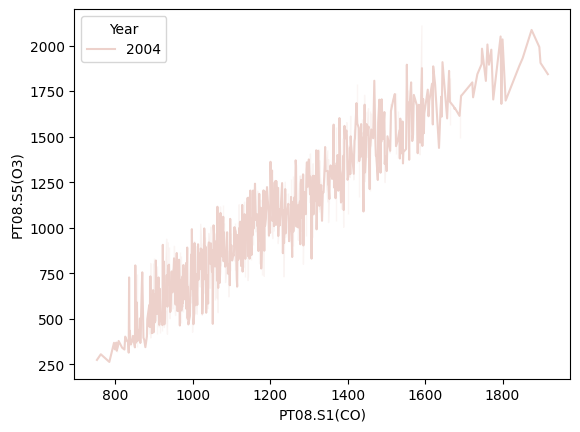

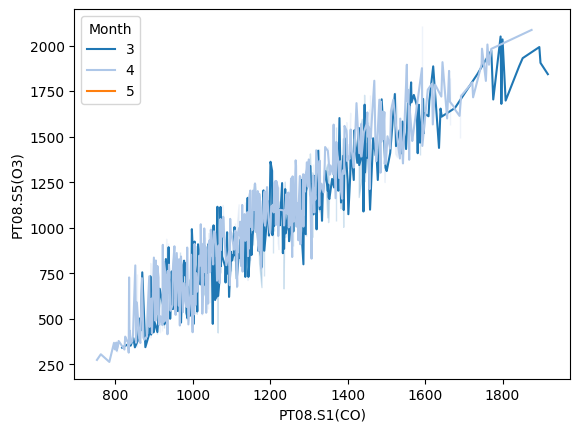

In [75]:
sns.lineplot(df, x='Month', y='NO2(GT)')
plt.show()
sns.lineplot(df, x='PT08.S1(CO)', y='PT08.S5(O3)', hue='Year')
plt.show()
sns.lineplot(df, x='PT08.S1(CO)', y='PT08.S5(O3)',
hue='Month', palette='tab20')
plt.show()

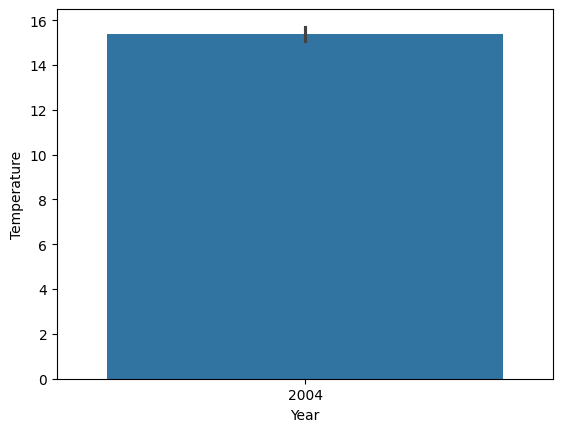

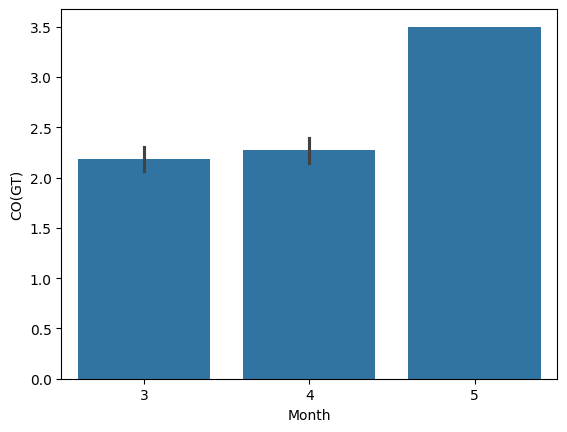

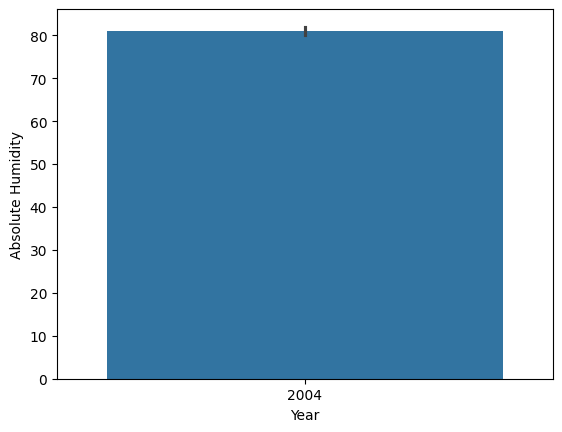

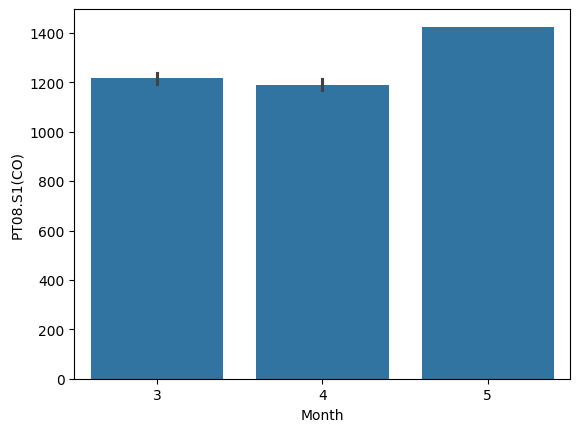

In [76]:
sns.barplot(df, x='Year', y='Temperature')
plt.show()
sns.barplot(df, x='Month', y='CO(GT)')
plt.show()
sns.barplot(df, x='Year', y='Absolute Humidity')
plt.show()
sns.barplot(df, x='Month', y='PT08.S1(CO)')
plt.show()

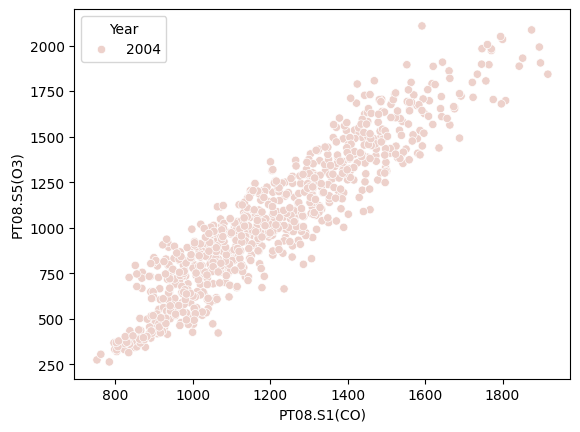

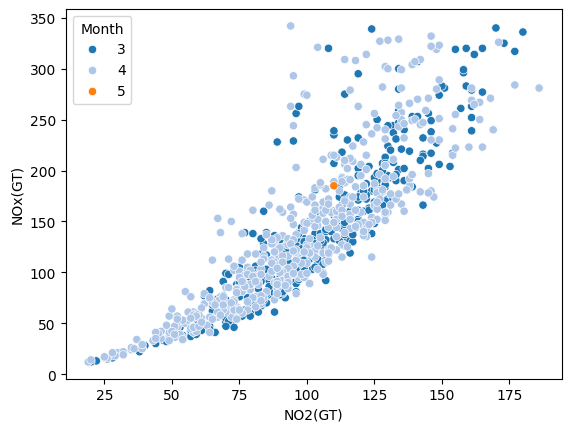

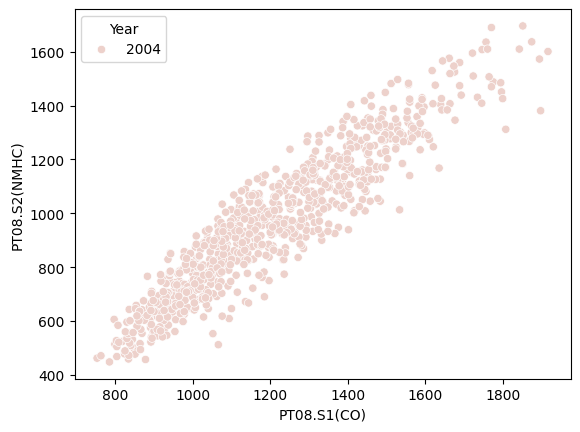

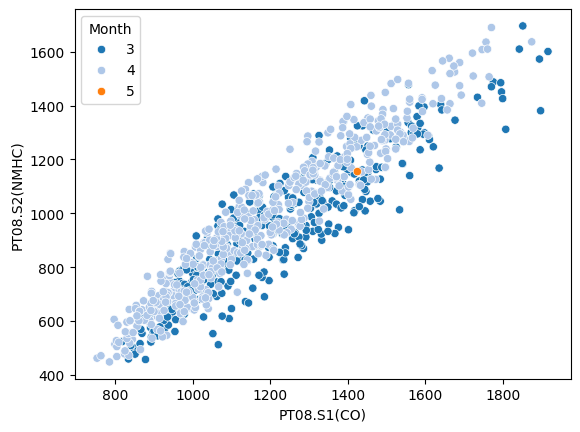

In [77]:
sns.scatterplot(df, x='PT08.S1(CO)', y='PT08.S5(O3)',
hue='Year')
plt.show()
sns.scatterplot(df, x='NO2(GT)', y='NOx(GT)', hue='Month',
palette='tab20')
plt.show()
sns.scatterplot(df, y='PT08.S2(NMHC)', x='PT08.S1(CO)',
hue='Year')
plt.show()
sns.scatterplot(df, y='PT08.S2(NMHC)', x='PT08.S1(CO)',
hue='Month', palette='tab20')
plt.show()

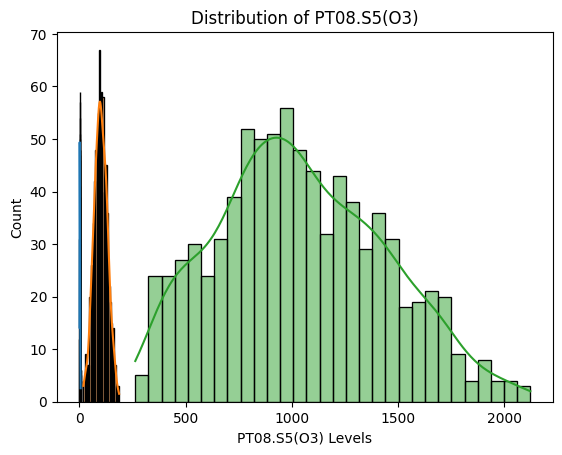

In [79]:
for col in ['CO(GT)', 'NO2(GT)', 'PT08.S5(O3)']:
  sns.histplot(df[col], kde=True, bins=30)
plt.title(f'Distribution of {col}')
plt.xlabel(f'{col} Levels')
plt.show()

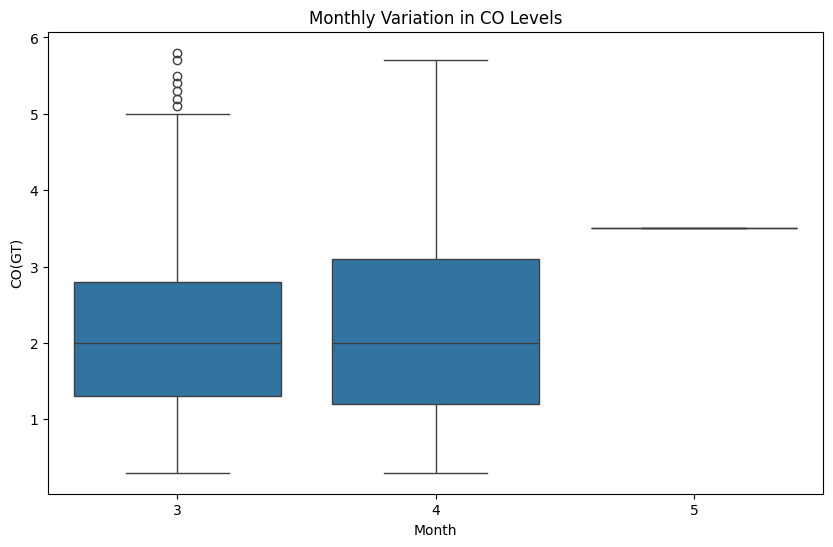

In [80]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Month', y='CO(GT)')
plt.title('Monthly Variation in CO Levels')
plt.xlabel('Month')
plt.ylabel('CO(GT)')
plt.show()

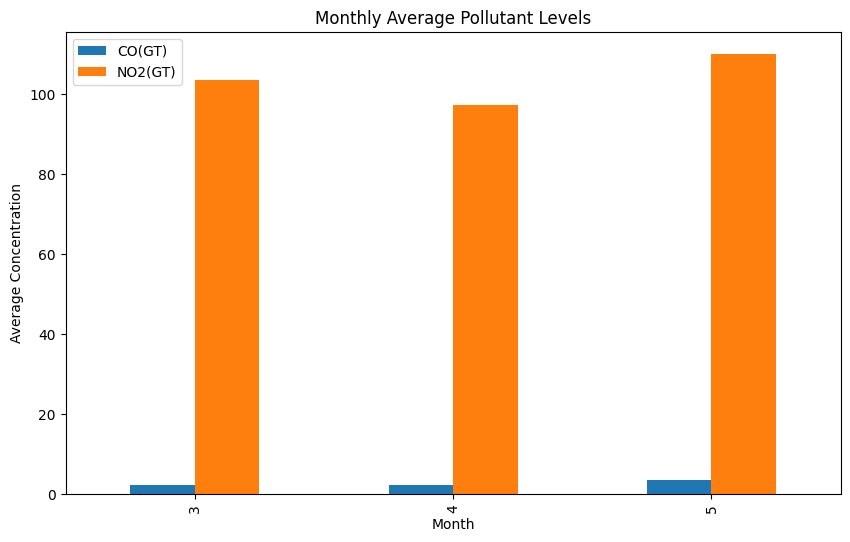

In [81]:
monthly_avg = df.groupby('Month')[['CO(GT)',
'NO2(GT)']].mean()
monthly_avg.plot(kind='bar', figsize=(10, 6))
plt.xlabel('Month')
plt.ylabel('Average Concentration')
plt.title('Monthly Average Pollutant Levels')
plt.legend()
plt.show()

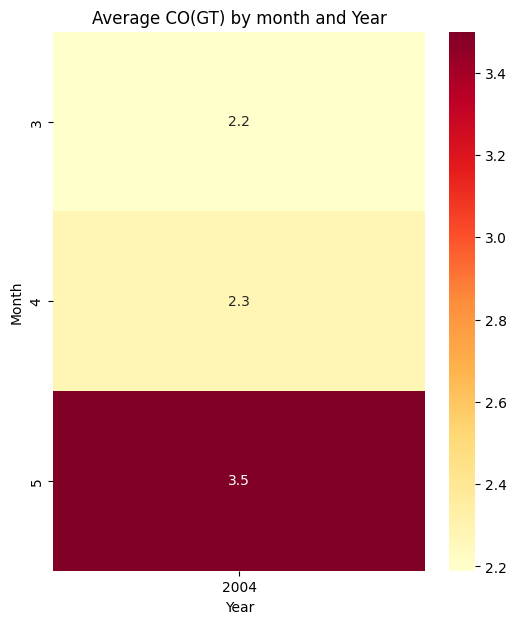

In [82]:
co_table = df.pivot_table(index='Month', columns='Year',
values='CO(GT)', aggfunc='mean')
plt.figure(figsize=(6, 7))
sns.heatmap(co_table, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Average CO(GT) by month and Year')
plt.show()